# 03 · 模型选择

回答三个问题：**用哪些模型**、**预测什么目标**、**怎样融合**。所有比较都用 01 的固定五折和同样的内层 10% 早停，看同一折上的配对差。

1. 早期基线：sklearn、LightGBM / CatBoost、v1、v2
2. CatBoost 的正则化参数（实验 07）
3. 其他模型、相对力量目标与三种堆叠方式（实验 08）
4. 目标变量工程：DOTS、IPF GL、异速生长（实验 08、14）
5. 其他模型大比较：Ridge、sklearn HGB、随机森林、ExtraTrees、TabPFN、EBM 等（实验 13）
6. cb_rel 的学习率（实验 12）

| notebook | 内容 |
|---|---|
| **01_data_exploration** | 读取与核对原始数据、探索分析、记录精度与「双胞胎」、数据质量检查、固定五折 |
| **02_feature_engineering** | 四轮特征（记录精度、跨地参赛、比赛背景、运动员历史与生涯、基于成绩的特征）及五折消融（实验 07、09、10、14） |
| **03_model_selection** | 早期基线、CatBoost 参数、其他模型与相对力量目标、堆叠方式、目标变量工程、模型大比较（实验 08、13） |
| **04_final_model** | 最终集成：8 个模型 × 5 折 × 3 种子 + 全量重训、NNLS 融合、双胞胎 + 同一运动员平滑、成对相似度平滑、提交文件（实验 11、12、15–17） |
| **05_error_analysis** | 最终残差、同一运动员与双胞胎结构、第二层做法比较、数据清洗实验、未采用的方法、交叉验证与公开榜 |

原始数据在 `data/`；结果保存在 `artifacts/` 下与 notebook 同名的目录。「实验 07–17」是实验的原始编号，代码注释和 RESULTS.md 沿用这些编号。

**训练开关**：默认全部为 `False`，只读取 `artifacts/` 中已保存的结果并生成表格和图，Colab 普通 CPU 运行时即可，几分钟跑完。

把某一项改为 `True` 并选择 **T4 GPU** 运行时，会按原协议重新训练对应的实验。每个模型训练完立即写入 `artifacts/`，断线后从头运行会跳过已完成的部分。**一次只打开一个开关**（不同实验的代码共用变量名），跑完后重启运行时再打开下一个。

In [1]:
TRAIN = {
    'model_zoo': False,       # 实验 08：RealMLP、TabM、cb_rel、lgb_rel + 堆叠 + 运动员平滑（GPU，约 1–1.5 小时）
    'model_compare': False,   # 实验 13：其他模型大比较 + 加入 HGB 的提交文件（GPU，约 1.5 小时）
}

实验 13 需要额外的包（EBM、TabPFN），要在导入 numpy 之前安装，所以这一格放在环境设置之前。

In [2]:
if TRAIN['model_compare']:
    import importlib
    import importlib.metadata
    import subprocess
    import sys

    EXTRA_PACKAGES = ['interpret-core', 'tabpfn']        # EBM、TabPFN
    missing = []
    for package in EXTRA_PACKAGES:
        try:
            importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            missing.append(package)
    if missing:
        result = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], text=True,
                                capture_output=True, check=False)
        print('pip 安装：', missing, '返回码', result.returncode)
        if result.returncode != 0:
            print(result.stderr[-2000:])
        importlib.invalidate_caches()
else:
    print("训练开关关闭（TRAIN['model_compare'] = False）：本节只读取 artifacts/ 中已保存的结果。")

训练开关关闭（TRAIN['model_compare'] = False）：本节只读取 artifacts/ 中已保存的结果。


In [3]:
# 环境、路径与通用设置（5 本 notebook 相同）
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib
import importlib.metadata
import inspect
import json
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import nnls
from sklearn.model_selection import KFold, train_test_split

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')


def find_project_dir():
    candidates = []
    if os.environ.get('PL_PROJECT_DIR'):
        candidates.append(Path(os.environ['PL_PROJECT_DIR']))
    candidates.append(Path('/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting'))
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    for candidate in candidates:
        if (candidate / 'data' / 'train.csv').is_file() and (candidate / 'data' / 'test.csv').is_file():
            return candidate.expanduser().resolve()
    raise FileNotFoundError('找不到项目目录（应包含 data/train.csv 与 data/test.csv）；请设置环境变量 PL_PROJECT_DIR')


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / 'data'                 # 原始 CSV（只读）
ARTIFACTS = PROJECT_DIR / 'artifacts'           # 每本 notebook 的结果在与它同名的子目录
SEED = 42                                       # 固定五折：KFold(5, shuffle=True, random_state=42)
N_FOLDS = 5
INNER_STOP_FRACTION = 0.10                      # 外层训练部分内留 10% 早停
MAX_ROUNDS = 20000
MODELS = ['lgb', 'xgb', 'catboost']             # 特征消融用的三个模型（每折内的运行顺序：快的先跑）
RUN_ONLY = None                                 # 只跑部分变体时写成列表；None 表示全部
KEEP_DELTA = -0.05                              # kg：平均 ΔRMSE ≤ −0.05 且 ≥ 4/5 折更好才保留
EXPECTED_SHA256 = {'train.csv': '62319814116506fb95a51f1185dbacdb170ab055642ee4c347a30584093d0856',
                   'test.csv': '563c6fa29f9e535740ef1f09b25954f00fbe242c81c0e5a7343dc18aa962ba46'}
CATBOOST_VERSION = '1.2.10'
GPU_NAME = None
VERSIONS = {'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

TRAIN = globals().get('TRAIN', {})              # 01 与 05 没有训练开关
if sum(bool(v) for v in TRAIN.values()) > 1:
    raise ValueError('一次只打开一个训练开关：不同实验的代码共用变量名。跑完一个、重启运行时后再打开下一个')
TRAINING = any(TRAIN.values())


def ensure_training_env():
    """只在训练时调用：安装固定版本的 CatBoost 与 pytabkit，导入训练用的库，确认 Colab 分配了 GPU。"""
    global catboost, lgb, xgb, torch, RealMLP_TD_Regressor, TabM_D_Regressor, PYTABKIT_ERROR, GPU_NAME, VERSIONS
    to_install = []
    try:
        installed_catboost = importlib.metadata.version('catboost')
    except importlib.metadata.PackageNotFoundError:
        installed_catboost = None
    if installed_catboost != CATBOOST_VERSION:
        if 'catboost' in sys.modules:
            raise RuntimeError('当前运行时已经导入另一版 CatBoost；请重启运行时后从头运行')
        to_install.append(f'catboost=={CATBOOST_VERSION}')
    try:
        importlib.metadata.version('pytabkit')
    except importlib.metadata.PackageNotFoundError:
        to_install.append('pytabkit')
    if to_install:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
        importlib.invalidate_caches()
    import catboost
    import lightgbm as lgb
    import torch
    import xgboost as xgb
    try:
        from pytabkit import RealMLP_TD_Regressor, TabM_D_Regressor
        PYTABKIT_ERROR = None
    except Exception as exc:                    # 安装或导入失败时其余模型照常运行
        RealMLP_TD_Regressor = TabM_D_Regressor = None
        PYTABKIT_ERROR = repr(exc)
    warnings.filterwarnings('ignore', category=UserWarning)
    if catboost.__version__ != CATBOOST_VERSION:
        raise RuntimeError(f'需要 CatBoost {CATBOOST_VERSION}；实际为 {catboost.__version__}')
    if shutil.which('nvidia-smi') is None or not torch.cuda.is_available():
        raise RuntimeError('训练需要 GPU：请在 Colab「更改运行时类型」中选择 T4 GPU 后从头运行')
    GPU_NAME = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                              text=True, capture_output=True, check=False).stdout.strip().splitlines()[0]
    VERSIONS = {'catboost': catboost.__version__, 'xgboost': xgb.__version__, 'lightgbm': lgb.__version__,
                'torch': torch.__version__,
                'pytabkit': None if PYTABKIT_ERROR else importlib.metadata.version('pytabkit'),
                'numpy': np.__version__, 'pandas': pd.__version__, 'python': sys.version.split()[0]}
    print('GPU         :', GPU_NAME)
    print('版本         :', VERSIONS)
    if PYTABKIT_ERROR:
        print('pytabkit 不可用，RealMLP / TabM 会在预检中跳过：', PYTABKIT_ERROR)


print(f'项目：{PROJECT_DIR}')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}')
if TRAINING:
    print('打开的训练开关：', [k for k, v in TRAIN.items() if v])

Mounted at /content/drive
项目：/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting
Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3


## 0. 读取数据；打开训练开关时重新生成特征（与 02 相同的代码）

In [4]:
def require(condition, message):
    if not bool(condition):
        raise ValueError(message)


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def rmse(a, b):
    a, b = np.asarray(a, dtype='float64'), np.asarray(b, dtype='float64')
    return float(np.sqrt(np.mean((a - b) ** 2)))


for name, expected in EXPECTED_SHA256.items():
    require(sha256_file(DATA_DIR / name) == expected, f'data/{name} 与原始数据不同；请检查数据文件')

TARGET = 'TotalKg'
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
RAW_FEATURES = [c for c in test.columns if c != 'id']
CAT = [c for c in RAW_FEATURES if c not in RAW_NUM]          # 不依赖 object / str dtype（pandas 2 与 3 都可用）
require(train.shape == (105000, 18) and test.shape == (45000, 17), '数据形状不符')
require(len(CAT) == 13 and all(pd.api.types.is_numeric_dtype(train[c]) for c in RAW_NUM)
        and not any(pd.api.types.is_numeric_dtype(train[c]) for c in CAT), '列分组不符')
require(not train[RAW_FEATURES].isna().any().any() and not test[RAW_FEATURES].isna().any().any(), '出现空值')
y = train[TARGET].to_numpy(dtype='float64')
n_train = len(train)

FOLD_IDS = np.zeros(n_train, dtype=int)
for k, (_, valid) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.arange(n_train)), start=1):
    FOLD_IDS[valid] = k
print(f'train {train.shape}  test {test.shape}；每折验证行数：{np.bincount(FOLD_IDS)[1:].tolist()}')

train (105000, 18)  test (45000, 17)；每折验证行数：[21000, 21000, 21000, 21000, 21000]


In [5]:
if TRAINING:
    both = pd.concat([train[RAW_FEATURES], test[RAW_FEATURES]], ignore_index=True)

    # F0：v2 的体重级别特征
    weight_class = pd.to_numeric(both['WeightClassKg'].str.replace('+', '', regex=False), errors='coerce')
    F0_EXTRA = pd.DataFrame({
        'WeightClass_num': weight_class,
        'Is_SHW': both['WeightClassKg'].str.endswith('+').astype('float64'),
        'BW_minus_Class': both['BodyweightKg'] - weight_class,
    })

    # P：记录精度（树按阈值切数值，学不到「是不是 .5」「是不是整数」）
    age2 = (both['Age'] * 2).round()
    require(np.allclose(both['Age'] * 2, age2), 'Age 不是 0.5 的整数倍')
    bw = both['BodyweightKg']
    is_int = np.isclose(bw, bw.round())
    is_1dec = np.isclose(bw * 10, (bw * 10).round())
    is_half = is_1dec & ~is_int & np.isclose((bw * 10).round() % 10, 5)
    pounds = bw / 0.45359237
    P = pd.DataFrame({
        'age_half': (age2 % 2).astype('float64'),
        'bw_precision': np.select([is_int, is_half, is_1dec], [0.0, 1.0, 2.0], default=3.0),
        'bw_lb_int': (np.abs(pounds - pounds.round()) < 0.015).astype('float64'),
    })

    # T：跨地参赛（居住地未知时为 NaN）
    abroad = (both['Country'] != both['MeetCountry']).astype('float64').where(both['Country'] != 'Unknown')
    state_known = ((both['State'] != 'Unknown') & (both['MeetState'] != 'Unknown')
                   & (both['Country'] == both['MeetCountry']))
    other_state = (both['State'] != both['MeetState']).astype('float64').where(state_known)
    T = pd.DataFrame({'abroad': abroad, 'other_state': other_state})

    # M：比赛背景；「比赛」≈ 联盟 × 年份 × 比赛国 × 比赛州（train+test 无标签统计）
    meet = (both['Federation'] + '|' + both['MeetYear'].astype(str) + '|'
            + both['MeetCountry'] + '|' + both['MeetState'])


    def by_meet(values):
        return values.groupby(meet).transform('mean')


    M = pd.DataFrame({
        'meet_n': meet.map(meet.value_counts()).astype('float64'),
        'meet_sexeq_n': both.groupby([meet, both['Sex'], both['Equipment']])['Age'].transform('size').astype('float64'),
        'fed_year_n': both.groupby(['Federation', 'MeetYear'])['Age'].transform('size').astype('float64'),
        'meet_share_other_state': by_meet(other_state),
        'meet_share_abroad': by_meet(abroad),
        'meet_share_age_half': by_meet(P['age_half']),
        'meet_share_equipped': by_meet((both['Equipment'] != 'Raw').astype('float64')),
        'meet_share_male': by_meet((both['Sex'] == 'M').astype('float64')),
        'meet_mean_age': by_meet(both['Age']),
    })

    BLOCKS = {'P': P, 'T': T, 'M': M}
    VARIANTS = {'F0': [], 'P': ['P'], 'T': ['T'], 'M': ['M'], 'PT': ['P', 'T'], 'ALL': ['P', 'T', 'M']}
    for name, frame in {'F0': F0_EXTRA, **BLOCKS}.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} 行数或索引不符')
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} 含无穷大')

    _FRAMES = {}


    def frames_for(variant, model):
        """(train, test) 特征表。CatBoost 的类别为字符串；LGB / XGB 为 category（词表来自 train+test，无标签）。"""
        kind = 'str' if model == 'catboost' else 'category'
        if (variant, kind) not in _FRAMES:
            frame = pd.concat([both[RAW_NUM], F0_EXTRA] + [BLOCKS[b] for b in VARIANTS[variant]] + [both[CAT]], axis=1)
            require(frame.columns.is_unique, f'{variant} 列名重复')
            frame[CAT] = frame[CAT].astype(str).astype(object) if kind == 'str' else frame[CAT].astype('category')
            _FRAMES[(variant, kind)] = (frame.iloc[:n_train].reset_index(drop=True),
                                        frame.iloc[n_train:].reset_index(drop=True))
        return _FRAMES[(variant, kind)]


    print({v: frames_for(v, 'lgb')[0].shape[1] for v in VARIANTS})
    summary_new = pd.concat([P, T, M], axis=1)
    display(pd.DataFrame({'train_mean': summary_new.iloc[:n_train].mean(), 'test_mean': summary_new.iloc[n_train:].mean(),
                          'nan_share': summary_new.isna().mean()}).round(4))


    _FRAMES.clear()                     # 07 的变体表不再需要，释放内存
    CORE9 = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
    sex, equipment = both['Sex'], both['Equipment']
    state = both['State'].where(both['State'] != 'Unknown')
    country = both['Country'].where(both['Country'] != 'Unknown')
    national = both['Federation'] + '|' + both['MeetYear'].astype(str) + '|' + both['MeetCountry']


    def counts(key):
        return key.map(key.value_counts()).astype('float64')


    def n_distinct(values, key):
        return values.groupby(key).transform('nunique').astype('float64')


    # M2：比赛背景加强（meet 与 by_meet 来自 07 的特征单元）
    M2 = pd.DataFrame({
        'meet_n_states': n_distinct(state, meet),
        'meet_n_countries': n_distinct(country, meet),
        'meet_n_wclass': n_distinct(both['WeightClassKg'], meet),
        'meet_share_tested': by_meet((both['Tested'] == 'Yes').astype('float64')),
        'meet_share_raw': by_meet((equipment == 'Raw').astype('float64')),
        'meet_share_multi': by_meet((equipment == 'Multi-ply').astype('float64')),
        'meet_share_bw2dec': by_meet((P['bw_precision'] == 3).astype('float64')),
        'meet_share_junior': by_meet((both['Age'] < 24).astype('float64')),
        'meet_share_master': by_meet((both['Age'] >= 40).astype('float64')),
        'meet_age_std': both['Age'].groupby(meet).transform('std'),
        'meet_sex_bw_mean': both['BodyweightKg'].groupby([meet, sex]).transform('mean'),
        'nat_n': counts(national),
        'nat_n_meetstates': n_distinct(both['MeetState'], national),
        'nat_n_states': n_distinct(state, national),
    })

    # D：组别背景
    division = meet + '|' + sex + '|' + equipment + '|' + both['WeightClassKg']
    age_division = meet + '|' + sex + '|' + equipment + '|' + both['AgeClass']
    exact_key = pd.Series(pd.util.hash_pandas_object(both[RAW_FEATURES], index=False).to_numpy())
    core_key = pd.Series(pd.util.hash_pandas_object(both[CORE9], index=False).to_numpy())
    D = pd.DataFrame({
        'div_n': counts(division),
        'div_bw_rank': both['BodyweightKg'].groupby(division).rank(pct=True),
        'div_age_rank': both['Age'].groupby(division).rank(pct=True),
        'agediv_n': counts(age_division),
        'dup_exact_n': counts(exact_key) - 1,
        'dup_core_n': counts(core_key) - 1,
    })

    # H：近似同一运动员的历史（出生年 = floor(MeetYear − Age)：x.5 年龄时恰为出生年，整数年龄可能差 1）
    valid = (both['Country'] != 'Unknown').to_numpy()
    birth = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int).astype(str)
    athlete = sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation'] + '|' + birth
    athlete0 = sex + '|' + both['Country'] + '|' + both['State'] + '|' + birth
    year = both['MeetYear'].astype('float64')
    H = pd.DataFrame({
        'ath_n': counts(athlete),
        'ath_n_years': n_distinct(year, athlete),
        'ath_years_since_first': year - year.groupby(athlete).transform('min'),
        'ath_years_to_last': year.groupby(athlete).transform('max') - year,
        'ath_n_equipment': n_distinct(equipment, athlete),
        'ath_bw_delta': both['BodyweightKg'] - both['BodyweightKg'].groupby(athlete).transform('mean'),
        'ath0_n': counts(athlete0),
        'ath0_n_feds': n_distinct(both['Federation'], athlete0),
    })
    H.loc[~valid] = np.nan


    # S：DOTS 系数（TotalKg = DOTS 分 × dots_scale）
    def dots_scale(sex_values, bw_values):
        s = np.asarray(sex_values).astype(str)
        bw = np.asarray(bw_values, dtype='float64')
        m, f = np.clip(bw, 40, 210), np.clip(bw, 40, 150)
        poly_m = -1.0930e-6 * m**4 + 7.391293e-4 * m**3 - 0.1918759221 * m**2 + 24.0900756 * m - 307.75076
        poly_f = -1.0706e-6 * f**4 + 5.158568e-4 * f**3 - 0.1126655495 * f**2 + 13.6175032 * f - 57.96288
        return np.where(s == 'M', poly_m, np.where(s == 'F', poly_f, 0.5 * (poly_m + poly_f))) / 500.0


    S = pd.DataFrame({'dots_scale': dots_scale(sex, both['BodyweightKg'])})

    # C：只给 CatBoost 的高基数 ID（有序目标统计编码）
    C = pd.DataFrame({'meet_id': meet, 'athlete_id': (athlete + '|' + equipment).where(valid, 'unknown')})

    BLOCKS2 = {'M2': M2, 'D': D, 'H': H, 'S': S}
    CB_ONLY = {'C': C}
    for name, frame in {**BLOCKS2, **CB_ONLY}.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} 行数或索引不符')
    for name, frame in BLOCKS2.items():
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} 含无穷大')
    require(S['dots_scale'].min() > 0.3, 'DOTS 系数异常')

    R1_BLOCKS = ['P', 'T', 'M']
    VARIANT_BLOCKS = {'R1': [], 'M2': ['M2'], 'D': ['D'], 'H': ['H'], 'S': ['S'], 'C': ['C']}
    MODELS_FOR = {'C': ['catboost']}      # C 只改变 CatBoost；融合时 LightGBM / XGBoost 用 R1
    SCREEN = [v for v in VARIANT_BLOCKS if RUN_ONLY is None or v in RUN_ONLY or v == 'R1']
    _FRAMES2 = {}


    def models_for(variant):
        return MODELS_FOR.get(variant, MODELS)


    def frames2(variant, model):
        """(train, test, 类别列)。R1 = F0 + P + T + M；C 块只加给 CatBoost。"""
        blocks = VARIANT_BLOCKS[variant]
        kind = 'str' if model == 'catboost' else 'category'
        key = (tuple(blocks), kind)
        if key not in _FRAMES2:
            nums = ([both[RAW_NUM], F0_EXTRA] + [BLOCKS[b] for b in R1_BLOCKS]
                    + [BLOCKS2[b] for b in blocks if b in BLOCKS2])
            cats = [both[CAT]] + ([CB_ONLY[b] for b in blocks if b in CB_ONLY] if kind == 'str' else [])
            frame = pd.concat(nums + cats, axis=1)
            require(frame.columns.is_unique, f'{variant} 列名重复')
            cat_cols = [c for part in cats for c in part.columns]
            if kind == 'str':
                frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
            else:
                frame[cat_cols] = frame[cat_cols].astype('category')
            _FRAMES2[key] = (frame.iloc[:n_train].reset_index(drop=True),
                             frame.iloc[n_train:].reset_index(drop=True), cat_cols)
        return _FRAMES2[key]


    new_cols = pd.concat([M2, D, H, S], axis=1)
    display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                          'nan_share': new_cols.isna().mean()}).round(4))
    print('C 块类别数：', {c: int(C[c].nunique()) for c in C.columns})
    print('各变体列数（LightGBM / XGBoost）：', {v: frames2(v, 'lgb')[0].shape[1] for v in VARIANT_BLOCKS if v != 'C'},
          '｜CatBoost C：', frames2('C', 'catboost')[0].shape[1])


    _FRAMES2.clear()                    # 09 的变体表不再需要，释放内存
    birth_num = np.floor(both['MeetYear'] - both['Age'] + 1e-9).astype(int)


    def fuzzy_count(prefix_key):
        """同前缀、出生年为 b−1、b、b+1 的行数（整数年龄推算的出生年可能差 1）。"""
        exact = prefix_key + '|' + birth_num.astype(str)
        table = exact.value_counts()
        total = exact.map(table).astype('float64')
        for d in (-1, 1):
            total = total + (prefix_key + '|' + (birth_num + d).astype(str)).map(table).fillna(0)
        return total


    # H2：运动员生涯（athlete、valid 来自 09 的特征单元；M、T 来自 07；M2 来自 09）
    bw = both['BodyweightKg']
    H2 = pd.DataFrame({
        'ath_max_meet_states': M2['meet_n_states'].groupby(athlete).transform('max'),
        'ath_mean_meet_states': M2['meet_n_states'].groupby(athlete).transform('mean'),
        'ath_max_meet_n': M['meet_n'].groupby(athlete).transform('max'),
        'ath_max_nat_states': M2['nat_n_states'].groupby(athlete).transform('max'),
        'ath_ever_abroad': T['abroad'].groupby(athlete).transform('max'),
        'ath_n_wclass': n_distinct(both['WeightClassKg'], athlete),
        'ath_bw_range': bw.groupby(athlete).transform('max') - bw.groupby(athlete).transform('min'),
        'ath_first_age': both['Age'].groupby(athlete).transform('min'),
        'ath_n_same_year': both.groupby([athlete, both['MeetYear']])['Age'].transform('size').astype('float64'),
        'ath_share_tested': (both['Tested'] == 'Yes').astype('float64').groupby(athlete).transform('mean'),
        'ath_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State'] + '|' + both['Federation']),
        'ath0_n_fuzzy': fuzzy_count(sex + '|' + both['Country'] + '|' + both['State']),
    })
    H2.loc[~valid] = np.nan

    # E：比赛的经验结构
    experience = H['ath_years_since_first']
    E = pd.DataFrame({
        'meet_mean_ath_n': H['ath_n'].groupby(meet).transform('mean'),
        'meet_mean_ath_exp': experience.groupby(meet).transform('mean'),
        'meet_share_veterans': (experience >= 3).astype('float64').where(experience.notna()).groupby(meet).transform('mean'),
        'meet_share_newcomers': (H['ath_n'] == 1).astype('float64').where(H['ath_n'].notna()).groupby(meet).transform('mean'),
    })

    ROUND3 = {'H2': H2, 'E': E}
    for name, frame in ROUND3.items():
        require(len(frame) == len(both) and frame.index.equals(both.index), f'{name} 行数或索引不符')
        require(not np.isinf(frame.to_numpy(dtype='float64')).any(), f'{name} 含无穷大')
    NUMERIC_BLOCKS = {**BLOCKS, **BLOCKS2, **ROUND3}          # P T M（07）、M2 D H S（09）、H2 E（本轮）
    R2_BLOCKS = ['P', 'T', 'M', 'H']                          # 09 的 ALL2
    EXTRAS = {'lgb': [], 'xgb': ['M2', 'S', 'D'], 'catboost': ['M2', 'C']}   # PM：09 中各模型单独有效的块
    VARIANTS3 = {'R2': [], 'H2': ['H2'], 'E': ['E'], 'PM': ['PM']}
    SCREEN3 = [v for v in VARIANTS3 if RUN_ONLY is None or v in RUN_ONLY or v == 'R2']
    _FRAMES3 = {}


    def blocks_for(variant, model):
        out = list(R2_BLOCKS)
        for b in VARIANTS3[variant]:
            out += EXTRAS[model] if b == 'PM' else [b]
        return out


    def runs(model, variant):
        """该模型在这个变体上的特征与 R2 不同才需要训练（例如 PM 对 LightGBM 没有变化）。"""
        return variant == 'R2' or blocks_for(variant, model) != blocks_for('R2', model)


    def frames3(variant, model):
        """(train, test, 类别列)。"""
        blocks = blocks_for(variant, model)
        kind = 'str' if model == 'catboost' else 'category'
        key = (tuple(blocks), kind)
        if key not in _FRAMES3:
            nums = [both[RAW_NUM], F0_EXTRA] + [NUMERIC_BLOCKS[b] for b in blocks if b in NUMERIC_BLOCKS]
            cats = [both[CAT]] + ([CB_ONLY[b] for b in blocks if b in CB_ONLY] if kind == 'str' else [])
            frame = pd.concat(nums + cats, axis=1)
            require(frame.columns.is_unique, f'{variant} {model} 列名重复')
            cat_cols = [c for part in cats for c in part.columns]
            if kind == 'str':
                frame[cat_cols] = frame[cat_cols].astype(str).astype(object)
            else:
                frame[cat_cols] = frame[cat_cols].astype('category')
            _FRAMES3[key] = (frame.iloc[:n_train].reset_index(drop=True),
                             frame.iloc[n_train:].reset_index(drop=True), cat_cols)
        return _FRAMES3[key]


    new_cols = pd.concat([H2, E], axis=1)
    display(pd.DataFrame({'train_mean': new_cols.iloc[:n_train].mean(), 'test_mean': new_cols.iloc[n_train:].mean(),
                          'nan_share': new_cols.isna().mean()}).round(4))
    print({f'{v}/{m}': frames3(v, m)[0].shape[1] for v in VARIANTS3 for m in MODELS if runs(m, v)})
else:
    print("没有打开训练开关：不需要重新生成特征，下面只读取已保存的结果。")

没有打开训练开关：不需要重新生成特征，下面只读取已保存的结果。


In [6]:
# 只读的结果工具：读取训练时保存的 summary_*.csv 和逐折预测，不训练
def read_summary(path, index_col=0):
    path = Path(path)
    if not path.is_file():
        print(f'缺少 {path.relative_to(PROJECT_DIR)}：请确认 artifacts/ 已从 Drive 同步，或打开对应的训练开关')
        return None
    return pd.read_csv(path, index_col=index_col)


def show(table, columns=None, digits=3):
    if table is not None:
        shown = table if columns is None else table[[c for c in columns if c in table.columns]]
        display(shown.round(digits))


def plot_fold_deltas(table, baseline, title):
    """配对比较表（列 mean_delta、d_fold1–5）：柱 = 五折平均 ΔRMSE，点 = 单折，虚线 = 保留门槛 −0.05。"""
    if table is None:
        return
    rows = table.drop(index=baseline, errors='ignore').sort_values('mean_delta', ascending=False)
    folds = rows[[f'd_fold{k}' for k in range(1, N_FOLDS + 1)]].to_numpy(dtype='float64')
    colours = ['#4c72b0' if v <= KEEP_DELTA else '#c44e52' if v > 0 else '#999999' for v in rows['mean_delta']]
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(rows) + 1.6))
    ax.barh(range(len(rows)), rows['mean_delta'], color=colours)
    for i in range(len(rows)):
        ax.scatter(folds[i], np.full(folds.shape[1], i), color='black', s=12, zorder=3)
    ax.axvline(0, color='black', lw=0.8)
    ax.axvline(KEEP_DELTA, color='#4c72b0', lw=0.8, ls='--')
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows.index.tolist())
    ax.set_xlabel(f'RMSE change vs {baseline} (kg); bar = 5-fold mean, dots = single folds')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def read_folds(directory, stem):
    """一个模型五折的 (OOF, 五折平均测试预测)；缺任何一折时返回 None。"""
    oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
    for k in range(1, N_FOLDS + 1):
        path = Path(directory) / f'{stem}__fold{k}.npz'
        if not path.is_file():
            return None
        saved = np.load(path)
        oof[saved['valid_idx']] = saved['val']
        test_pred += saved['test'] / N_FOLDS
    return (oof, test_pred) if not np.isnan(oof).any() else None

## 1. 早期基线

项目开始时的几次尝试（代码在 Git 历史第一个提交的 `modeling.ipynb`、`pipeline.ipynb`、`colab_gpu_pipeline*.ipynb` 中）：

- 四类梯度提升 / 神经网络模型单独都在 78.1–78.4，OOF 相关 0.990–0.995，瓶颈在特征的信息量。
- 多种子平均对神经网络帮助很大：v2 中 MLP 单种子 80.05 → 3 种子 78.40。
- v1、v2 用外层验证折早停，交叉验证偏乐观：v2 的 CV→公开榜差约 +0.5；实验 07 起改用内层早停，差缩小到 +0.13 到 +0.25。

In [7]:
baselines = pd.DataFrame([
    ('sklearn GradientBoosting（序号编码类别）', '5 折，折均值', 82.60, '约 80'),
    ('LightGBM / CatBoost 融合（本地 CPU）', '5 折，外层折早停', 77.766, '—'),
    ('v1：XGBoost + CatBoost + MLP，NNLS（Colab GPU）', '5 折，外层折早停', 77.775, 78.0),
    ('v2：LightGBM ×1 + XGBoost ×3 + CatBoost ×3 + MLP ×3 种子，NNLS', '10 折，外层折早停', 77.302, 77.799),
    ('v2 单模型：LightGBM / XGBoost / CatBoost / MLP', '同上', '78.189 / 78.432 / 78.093 / 78.395', '—'),
], columns=['模型', '协议', 'CV RMSE', '公开榜'])
display(baselines.set_index('模型'))

,协议,CV RMSE,公开榜
模型,,,
sklearn GradientBoosting（序号编码类别）,5 折，折均值,82.6,约 80
LightGBM / CatBoost 融合（本地 CPU）,5 折，外层折早停,77.766,—
v1：XGBoost + CatBoost + MLP，NNLS（Colab GPU）,5 折，外层折早停,77.775,78.0
v2：LightGBM ×1 + XGBoost ×3 + CatBoost ×3 + MLP ×3 种子，NNLS,10 折，外层折早停,77.302,77.799
v2 单模型：LightGBM / XGBoost / CatBoost / MLP,同上,78.189 / 78.432 / 78.093 / 78.395,—


## 2. CatBoost 的正则化参数（实验 07）

在第一轮最佳特征 ALL 上比较：
- `C1`：v2 参数，depth 8、L2 3；
- `C2`：depth 8、L2 10、Bernoulli 抽样 0.8；
- `C3`：depth 6、L2 10、Bernoulli 0.8。

训练代码在 02 的第一轮训练开关里。

In [8]:
print('CatBoost 参数，特征 ALL，五折配对（基线 C1 = v2 参数）：')
show(read_summary(ARTIFACTS / '02_feature_engineering' / 'round1' / 'summary_catboost_params.csv'),
     ['oof_rmse', 'mean_delta', 'folds_better', 'keep', 'd_fold1', 'd_fold2', 'd_fold3', 'd_fold4', 'd_fold5'])

CatBoost 参数，特征 ALL，五折配对（基线 C1 = v2 参数）：


,oof_rmse,mean_delta,folds_better,keep,d_fold1,d_fold2,d_fold3,d_fold4,d_fold5
variant,,,,,,,,,
C2,77.846,-0.219,5,True,-0.079,-0.087,-0.395,-0.377,-0.158
C3,77.890,-0.175,5,True,-0.069,-0.022,-0.381,-0.246,-0.156
C1,78.065,0.000,0,False,0.000,0.000,0.000,0.000,0.000


**结论**：**C2 −0.22（5/5 折）**，C3 −0.17。之后所有 CatBoost 都用 C2。

## 3. 其他模型、相对力量目标与堆叠（实验 08）

| 模型 | 为什么可能有用 |
|---|---|
| `realmlp`：RealMLP-TD（pytabkit，NeurIPS 2024） | 调好默认参数的 MLP，比 v2 自写的 MLP 强得多 |
| `tabm`：TabM（pytabkit，ICLR 2025） | 一次训练 32 个共享权重的 MLP，加分段线性数值嵌入，正好解决神经网络方差大的问题 |
| `cb_rel`、`lgb_rel`：相对力量目标 | 先用 DOTS 公式把 TotalKg 换成相对力量，模型预测「这个人相对多强」，再乘回 kg |

相对力量目标的样本按系数² 加权，所以模型仍然在最小化 kg 的 RMSE。乘法结构与普通模型的加法结构不同，错误也不同。

堆叠方式在同一五折上嵌套比较：全局 NNLS、按性别 × 装备分段 NNLS、残差元模型（小 LightGBM）。同一运动员平滑的结果在 05。

**没放进来的**：
- TabPFN-2.5：面向 ≤ 5 万行，建议用 A100 / H100；
- TabR：需要 faiss；
- AutoGluon：在 T4 上内存不足；
- log 目标：对 kg 的 RMSE 有系统偏差。

In [9]:
if TRAIN['model_zoo']:
    ensure_training_env()
    # 实验 08 的设置（结果目录：原 artifacts/model_zoo_v1_ALL）
    OUTPUT_DIR = ARTIFACTS / '03_model_selection' / 'model_zoo'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    FEATURE_SET = 'ALL'        # 实验 07 融合最好的特征变体（F0 + P + T + M）
    ZOO = ['lgb_rel', 'cb_rel', 'realmlp', 'tabm']   # 每折内的运行顺序：快的先跑
    RUN_ONLY = None            # 例如 ['realmlp']；None 表示全部
    STAGE2_MIN_GAIN = 0.02     # kg：运动员平滑在交叉拟合下至少改善这么多才用于提交文件
    R1_DIR = ARTIFACTS / '02_feature_engineering' / 'round1'      # 实验 07 的结果
    V2_DIR = ARTIFACTS / '03_model_selection' / 'baseline_v2'     # v2 的逐折预测（原 outputs_v2）
    require(FEATURE_SET in VARIANTS, f'未知特征变体：{FEATURE_SET}；可选 {list(VARIANTS)}')
    X_cat, Xt_cat = frames_for(FEATURE_SET, 'lgb')        # 类别为 category：LightGBM、神经网络
    X_str, Xt_str = frames_for(FEATURE_SET, 'catboost')   # 类别为字符串：CatBoost
    NUM_COLS = [c for c in X_cat.columns if c not in CAT]
    NAN_COLS = [c for c in NUM_COLS if X_cat[c].isna().any() or Xt_cat[c].isna().any()]
    print(f'特征变体 {FEATURE_SET}：{X_cat.shape[1]} 列 = {len(NUM_COLS)} 数值（{len(NAN_COLS)} 列有缺失）+ {len(CAT)} 类别')

    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)                   # = v2 / 07
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=3.0, random_strength=1.0, bagging_temperature=1.0,
                     border_count=128)                                                    # = v2 / 07 的 C1
    NN_COMMON = dict(device='cuda', random_state=SEED, n_cv=1, n_refit=0, verbosity=0)
    NN_PARAMS = {'realmlp': dict(NN_COMMON), 'tabm': dict(NN_COMMON, num_emb_type='pwl')}
    NN_FALLBACK = {'tabm': dict(NN_COMMON)}         # 预检失败时去掉分段线性数值嵌入


    def dots_scale(frame):
        """DOTS 系数的分母 / 500：TotalKg = DOTS 分 × scale。体重截断到公式的有效范围；Mx 取男女平均。"""
        sex = frame['Sex'].astype(str).to_numpy()
        bw = frame['BodyweightKg'].to_numpy(dtype='float64')
        m, f = np.clip(bw, 40, 210), np.clip(bw, 40, 150)
        poly_m = -1.0930e-6 * m**4 + 7.391293e-4 * m**3 - 0.1918759221 * m**2 + 24.0900756 * m - 307.75076
        poly_f = -1.0706e-6 * f**4 + 5.158568e-4 * f**3 - 0.1126655495 * f**2 + 13.6175032 * f - 57.96288
        return np.where(sex == 'M', poly_m, np.where(sex == 'F', poly_f, 0.5 * (poly_m + poly_f))) / 500.0


    SCALE, SCALE_TEST = dots_scale(train), dots_scale(test)
    require(np.isfinite(SCALE).all() and np.isfinite(SCALE_TEST).all() and min(SCALE.min(), SCALE_TEST.min()) > 0.3,
            'DOTS 系数异常')
    relative = y / SCALE
    print(f'变异系数：kg 目标 {y.std() / y.mean():.3f} → 相对力量 {relative.std() / relative.mean():.3f}')


    def nn_frames(*frames):
        """神经网络输入：数值缺失用第一个表（外层训练部分）的中位数填补并加缺失标记；类别保持 category。"""
        median = frames[0][NUM_COLS].median()
        out = []
        for frame in frames:
            z = frame.copy()
            for c in NAN_COLS:
                z[f'{c}_isna'] = z[c].isna().astype('float64')
            z[NUM_COLS] = z[NUM_COLS].fillna(median).fillna(0.0)
            out.append(z.reset_index(drop=True))
        return out


    def fit_model(name, a, s, v, test_rows=None, rounds=MAX_ROUNDS, nn_overrides=None):
        """a / s / v：内层拟合 / 内层早停 / 外层验证 的训练行号。返回 (验证预测, 测试预测, 最佳轮数或 None)。"""
        Xt_c = Xt_cat if test_rows is None else Xt_cat.iloc[test_rows]
        Xt_s = Xt_str if test_rows is None else Xt_str.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        if name in ('lgb_rel', 'cb_rel'):
            wa, ws = SCALE[a] ** 2, SCALE[s] ** 2        # 相对力量误差 × scale = kg 误差，所以按 scale² 加权
            norm = wa.mean()
            wa, ws = wa / norm, ws / norm
            ra, rs = y[a] / SCALE[a], y[s] / SCALE[s]
            if name == 'lgb_rel':
                m = lgb.LGBMRegressor(n_estimators=rounds, random_state=SEED, n_jobs=-1, **LGB_PARAMS)
                m.fit(X_cat.iloc[a], ra, sample_weight=wa, eval_set=[(X_cat.iloc[s], rs)], eval_sample_weight=[ws],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
                best = int(m.best_iteration_ or rounds)
                p_val, p_test = m.predict(X_cat.iloc[v], num_iteration=best), m.predict(Xt_c, num_iteration=best)
            else:
                cats = [c for c in X_str.columns if c in CAT]
                m = catboost.CatBoostRegressor(iterations=rounds, loss_function='RMSE', eval_metric='RMSE',
                                               od_type='Iter', od_wait=300, random_seed=SEED, verbose=0,
                                               task_type='GPU', devices='0', allow_writing_files=False, **CB_PARAMS)
                m.fit(catboost.Pool(X_str.iloc[a], ra, cat_features=cats, weight=wa),
                      eval_set=catboost.Pool(X_str.iloc[s], rs, cat_features=cats, weight=ws), use_best_model=True)
                best = int(m.get_best_iteration()) + 1
                p_val, p_test = m.predict(X_str.iloc[v]), m.predict(Xt_s)
            return np.asarray(p_val, dtype='float64') * SCALE[v], np.asarray(p_test, dtype='float64') * scale_t, best
        cls = {'realmlp': RealMLP_TD_Regressor, 'tabm': TabM_D_Regressor}[name]
        require(cls is not None, f'pytabkit 不可用：{PYTABKIT_ERROR}')
        params = dict(NN_PARAMS[name], **(nn_overrides or {}))
        unknown = set(params) - set(inspect.signature(cls.__init__).parameters)
        require(not unknown, f'{name} 不支持参数 {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_cat.iloc[a], X_cat.iloc[s], X_cat.iloc[v], Xt_c)
        mu, sd = y[a].mean(), y[a].std()
        m = cls(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CAT])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test, None


    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    for name in ZOO:
        for attempt in (['main', 'fallback'] if name in NN_FALLBACK else ['main']):
            if attempt == 'fallback':
                NN_PARAMS[name] = dict(NN_FALLBACK[name])
            started = time.perf_counter()
            try:
                p_val, p_test, _ = fit_model(name, pa, ps, pv, test_rows=np.arange(500), rounds=30,
                                             nn_overrides={'n_epochs': 3})
                require(len(p_val) == len(pv) and len(p_test) == 500, '预测长度不符')
                require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), '预测含非有限值')
                failed.pop(name, None)
                print(f'预检通过：{name:8s}（{attempt}）RMSE {rmse(y[pv], p_val):.1f}，用时 {time.perf_counter() - started:.0f}s')
                break
            except Exception as exc:
                failed[name] = repr(exc)
                print(f'预检失败：{name}（{attempt}）→ {exc!r}')
    print('将运行：', [n for n in ZOO if n not in failed], '；跳过：', failed or '无')


    CONFIG = {'purpose': 'model zoo on the 07 folds; inner 10% early stop (same split as 07); score on outer fold',
              'feature_set': FEATURE_SET, 'seed': SEED, 'n_folds': N_FOLDS,
              'inner_stop_fraction': INNER_STOP_FRACTION, 'data_sha256': EXPECTED_SHA256}
    config_path = OUTPUT_DIR / 'config.json'
    if config_path.is_file():
        require(json.loads(config_path.read_text(encoding='utf-8')) == CONFIG,
                f'{OUTPUT_DIR.name} 已有不同配置的结果；改动配置时请改 EXPERIMENT_ID')
    else:
        config_path.write_text(json.dumps(CONFIG, ensure_ascii=False, indent=1), encoding='utf-8')


    def spec_of(name):
        params = LGB_PARAMS if name == 'lgb_rel' else CB_PARAMS if name == 'cb_rel' else NN_PARAMS[name]
        return {'model': name, 'variant': FEATURE_SET, 'columns': list(X_cat.columns), 'params': dict(params),
                'target': 'dots_relative_weighted' if name.endswith('_rel') else 'standardized_kg'}


    def run_one(name, fold):
        json_path, npz_path = OUTPUT_DIR / f'{name}__fold{fold}.json', OUTPUT_DIR / f'{name}__fold{fold}.npz'
        spec = spec_of(name)
        if json_path.is_file() and npz_path.is_file():
            saved = json.loads(json_path.read_text(encoding='utf-8'))
            require(saved['spec'] == spec, f'{name} fold {fold} 的定义已改变；请改 EXPERIMENT_ID')
            return saved, 'cache'
        fit_idx = np.flatnonzero(FOLD_IDS != fold)
        valid_idx = np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 07
        started = time.perf_counter()
        p_val, p_test, best = fit_model(name, inner_fit, inner_stop, valid_idx)
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{name} fold {fold} 预测含非有限值')
        np.savez(npz_path, valid_idx=valid_idx, val=p_val, test=p_test)
        result = {'model': name, 'fold': fold, 'spec': spec, 'best_iteration': best,
                  'rmse': rmse(y[valid_idx], p_val), 'seconds': time.perf_counter() - started,
                  'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        json_path.write_text(json.dumps(result, ensure_ascii=False, indent=1), encoding='utf-8')
        return result, f'{result["seconds"]:.0f}s'


    selected = [n for n in ZOO if (RUN_ONLY is None or n in RUN_ONLY) and n not in failed]
    for fold in range(1, N_FOLDS + 1):
        fold_started = time.perf_counter()
        for name in selected:
            result, how = run_one(name, fold)
            best = result['best_iteration']
            print(f'fold {fold}  {name:8s}  RMSE {result["rmse"]:.3f}' + (f'  最佳轮数 {best}' if best else '') + f'  ({how})')
        print(f'—— fold {fold} 完成，本次运行用时 {(time.perf_counter() - fold_started) / 60:.1f} 分钟')


    def load_oof(directory, stem):
        oof, pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = directory / f'{stem}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            pred += saved['test'] / N_FOLDS
        require(not np.isnan(oof).any(), f'{stem} 的 OOF 不完整')
        return oof, pred


    def fold_rmse(pred):
        return np.array([rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)])


    MODELS = {}
    for tag in ['lgb', 'xgb', 'catboost_C1', 'catboost_C2', 'catboost_C3']:
        loaded = load_oof(R1_DIR, f'{tag}__{FEATURE_SET}')
        if loaded is not None:
            MODELS[f'07_{tag}'] = loaded
    BASE_NAMES = list(MODELS)
    for name in ZOO:
        loaded = load_oof(OUTPUT_DIR, name)
        if loaded is not None:
            MODELS[name] = loaded
    require(MODELS, '还没有任何完成的模型')
    print('07 的模型：', BASE_NAMES or '无（07 未完成或特征变体不同）', '｜本 notebook 的模型：',
          [n for n in ZOO if n in MODELS])


    def nnls_oof(names_):
        P_ = np.column_stack([MODELS[n][0] for n in names_])
        w, _ = nnls(P_, y)
        return P_ @ w


    base_oof = nnls_oof(BASE_NAMES) if BASE_NAMES else None
    rows = []
    for name, (oof, _) in MODELS.items():
        row = {'model': name, 'oof_rmse': rmse(y, oof), **{f'fold{k}': v for k, v in enumerate(fold_rmse(oof), 1)}}
        if base_oof is not None and name not in BASE_NAMES:
            blended = nnls_oof(BASE_NAMES + [name])
            row.update({'corr_with_07_blend': float(np.corrcoef(oof, base_oof)[0, 1]),
                        'blend_with_07': rmse(y, blended),
                        'delta_vs_07_blend': rmse(y, blended) - rmse(y, base_oof),
                        'folds_better': int((fold_rmse(blended) < fold_rmse(base_oof)).sum())})
        rows.append(row)
    standalone = pd.DataFrame(rows).set_index('model').sort_values('oof_rmse')
    if base_oof is not None:
        print(f'07 模型的 NNLS 融合 OOF RMSE：{rmse(y, base_oof):.3f}')
    display(standalone.round(3))
    standalone.to_csv(OUTPUT_DIR / 'summary_models.csv')

    # ---- 三种堆叠方式，五折嵌套 ----
    NAMES = list(MODELS)
    P = np.column_stack([MODELS[n][0] for n in NAMES])
    PT = np.column_stack([MODELS[n][1] for n in NAMES])
    segment = (both['Sex'].astype(str) + '|' + both['Equipment'].astype(str)).to_numpy()
    SEG, SEG_T = segment[:n_train], segment[n_train:]
    META = pd.DataFrame({'Sex': both['Sex'].astype(str).astype('category'),
                         'Equipment': both['Equipment'].astype(str).astype('category'),
                         'BodyweightKg': both['BodyweightKg'].to_numpy(dtype='float64'),
                         'Age': both['Age'].to_numpy(dtype='float64')})
    META_TR, META_TE = META.iloc[:n_train].reset_index(drop=True), META.iloc[n_train:].reset_index(drop=True)
    META_PARAMS = dict(n_estimators=300, learning_rate=0.02, num_leaves=15, min_child_samples=500, subsample=0.8,
                       subsample_freq=1, reg_lambda=10.0, random_state=SEED, n_jobs=-1, verbose=-1)


    def global_nnls(fit, apply_P):
        w, _ = nnls(P[fit], y[fit])
        return apply_P @ w


    def segment_nnls(fit, apply_P, apply_seg, min_rows=3000):
        out = global_nnls(fit, apply_P)
        for s in np.unique(apply_seg):
            m_fit = fit & (SEG == s)
            if m_fit.sum() >= min_rows:
                w_s, _ = nnls(P[m_fit], y[m_fit])
                m_apply = apply_seg == s
                out[m_apply] = apply_P[m_apply] @ w_s
        return out


    def residual_meta(fit, apply_P, apply_meta):
        """先全局 NNLS，再用小 LightGBM 按性别 / 装备 / 体重 / 年龄 / 模型分歧修正残差。"""
        w, _ = nnls(P[fit], y[fit])
        base_fit, base_apply = P[fit] @ w, apply_P @ w
        X_fit = META_TR[fit].assign(blend=base_fit, spread=P[fit].std(axis=1))
        X_apply = apply_meta.reset_index(drop=True).assign(blend=base_apply, spread=apply_P.std(axis=1))
        model = lgb.LGBMRegressor(**META_PARAMS).fit(X_fit, y[fit] - base_fit)
        return base_apply + model.predict(X_apply)


    METHODS = {
        'global_nnls': lambda fit, va: global_nnls(fit, P[va]),
        'segment_nnls': lambda fit, va: segment_nnls(fit, P[va], SEG[va]),
        'residual_meta': lambda fit, va: residual_meta(fit, P[va], META_TR[va]),
    }
    HONEST = {}
    for method, fn in METHODS.items():
        pred = np.zeros(n_train)
        for k in range(1, N_FOLDS + 1):
            fit, va = FOLD_IDS != k, FOLD_IDS == k
            pred[va] = fn(fit, va)
        HONEST[method] = pred
    stack_table = pd.DataFrame({m: {'nested_oof_rmse': rmse(y, p), **{f'fold{k}': v for k, v in enumerate(fold_rmse(p), 1)}}
                                for m, p in HONEST.items()}).T.sort_values('nested_oof_rmse')
    display(stack_table.round(3))
    stack_table.to_csv(OUTPUT_DIR / 'summary_stacking.csv')
    BEST_METHOD = stack_table.index[0]
    everything = np.ones(n_train, dtype=bool)
    STACK_TEST = {'global_nnls': lambda: global_nnls(everything, PT),
                  'segment_nnls': lambda: segment_nnls(everything, PT, SEG_T),
                  'residual_meta': lambda: residual_meta(everything, PT, META_TE)}[BEST_METHOD]()
    STACK_OOF = HONEST[BEST_METHOD]
    print(f'选用的堆叠方式：{BEST_METHOD}（嵌套 OOF RMSE {rmse(y, STACK_OOF):.3f}），使用 {len(NAMES)} 个模型：{NAMES}')


    CORE = ['Age', 'BodyweightKg', 'MeetYear', 'Sex', 'Federation', 'MeetCountry', 'MeetState', 'Country', 'State']
    ATHLETE_KEYS = {
        'A0': ['Sex', 'Country', 'State', 'birth_year'],
        'A1': ['Sex', 'Country', 'State', 'Federation', 'birth_year'],
        'A2': ['Sex', 'Country', 'State', 'Federation', 'birth_year', 'Equipment'],
        'A3': ['Sex', 'Country', 'State', 'Federation', 'birth_year', 'Equipment', 'WeightClassKg'],
        'M2': ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment'],
    }
    SHRINK = {'A0': 5.0, 'A1': 5.0, 'A2': 3.0, 'A3': 2.0, 'M2': 20.0}


    def keyed(frame):
        out = frame[RAW_FEATURES].copy()
        out['birth_year'] = np.floor(out['MeetYear'] - out['Age'] + 1e-9)
        return out


    def row_keys(frame, columns):
        return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


    KT, KQ = keyed(train), keyed(test)
    EX_TR, EX_TE = row_keys(KT, RAW_FEATURES), row_keys(KQ, RAW_FEATURES)
    CO_TR, CO_TE = row_keys(KT, CORE), row_keys(KQ, CORE)
    AK_TR = {k: row_keys(KT, cols) for k, cols in ATHLETE_KEYS.items()}
    AK_TE = {k: row_keys(KQ, cols) for k, cols in ATHLETE_KEYS.items()}
    VALID_TR = (train['Country'] != 'Unknown').to_numpy(dtype='float64')
    VALID_TE = (test['Country'] != 'Unknown').to_numpy(dtype='float64')
    HALF = (AK_TR['A0'] % 2).astype(int)


    def group_sum(keys_tr, values, keys_query=None):
        """训练行：同键其他训练行（不含自己）的和与个数；查询行：同键全部训练行的和与个数。"""
        table = pd.DataFrame({'k': keys_tr, 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
        if keys_query is None:
            k = pd.Series(keys_tr)
            return k.map(table['sum']).to_numpy() - values, k.map(table['count']).to_numpy() - 1
        k = pd.Series(keys_query)
        return k.map(table['sum']).fillna(0).to_numpy(), k.map(table['count']).fillna(0).to_numpy()


    def twin_mates(query=False):
        s_ex, n_ex = group_sum(EX_TR, y, EX_TE if query else None)
        s_co, n_co = group_sum(CO_TR, y, CO_TE if query else None)
        level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
        mate = np.where(level == 'exact', s_ex / np.maximum(n_ex, 1), s_co / np.maximum(n_co, 1))
        return level, mate


    TW_LEVEL, TW_MATE = twin_mates()
    TW_LEVEL_T, TW_MATE_T = twin_mates(query=True)


    def fit_alpha(mask, pred):
        d = TW_MATE[mask] - pred[mask]
        denom = float(np.sum(d * d))
        return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


    def apply_twins(pred, level, mate, alphas):
        out = pred.copy()
        for lv, a in alphas.items():
            m = level == lv
            out[m] = pred[m] + a * (mate[m] - pred[m])
        return out


    def athlete_features(residual, query=False):
        cols = []
        for k in ATHLETE_KEYS:
            s, n = group_sum(AK_TR[k], residual, AK_TE[k] if query else None)
            f = s / (n + SHRINK[k])
            if k != 'M2':
                f = f * (VALID_TE if query else VALID_TR)
            cols.append(f)
        return np.column_stack(cols)


    def stage2(oof, test_pred, label):
        alphas = {lv: fit_alpha(TW_LEVEL == lv, oof) for lv in ['exact', 'core']}
        p1 = apply_twins(oof, TW_LEVEL, TW_MATE, alphas)
        p1_cf = oof.copy()
        for h in (0, 1):
            a_h = {lv: fit_alpha((HALF != h) & (TW_LEVEL == lv), oof) for lv in ['exact', 'core']}
            m = HALF == h
            p1_cf[m] = apply_twins(oof[m], TW_LEVEL[m], TW_MATE[m], a_h)
        t1 = apply_twins(test_pred, TW_LEVEL_T, TW_MATE_T, alphas)

        r1 = y - p1
        F, FT = athlete_features(r1), athlete_features(r1, query=True)
        p2_cf = p1_cf.copy()
        for h in (0, 1):
            fit, m = HALF != h, HALF == h
            beta_h = np.linalg.lstsq(F[fit], r1[fit], rcond=None)[0]
            p2_cf[m] = p1_cf[m] + F[m] @ beta_h
        beta = np.linalg.lstsq(F, r1, rcond=None)[0]
        gain = rmse(y, p1_cf) - rmse(y, p2_cf)
        use_athlete = bool(gain >= STAGE2_MIN_GAIN)
        t2 = t1 + FT @ beta if use_athlete else t1.copy()
        row = {'base': label, 'oof_rmse': rmse(y, oof), 'twins_crossfit': rmse(y, p1_cf),
               'twins_athlete_crossfit': rmse(y, p2_cf), 'athlete_gain': gain, 'athlete_used': use_athlete,
               'alpha_exact': alphas['exact'], 'alpha_core': alphas['core'],
               **{f'beta_{k}': float(b) for k, b in zip(ATHLETE_KEYS, beta)},
               'test_rows_twins': int((TW_LEVEL_T != 'none').sum()),
               'test_mean_abs_athlete_adj': float(np.abs(t2 - t1).mean())}
        return row, {'base': test_pred, 'twins': t1, 'final': t2}


    rows, exports = [], {}
    row, preds = stage2(STACK_OOF, STACK_TEST, f'08 五折堆叠（{BEST_METHOD}）')
    rows.append(row)
    exports['zoo5f'] = preds

    V2_SEEDS = {'lgb': [42], 'xgb': [42, 7, 2024], 'catboost': [42, 7, 2024], 'mlp': [42, 7, 2024]}
    try:
        oofs, tests = [], []
        for model, seeds in V2_SEEDS.items():
            oof, pred = np.zeros(n_train), np.zeros(len(test))
            for seed in seeds:
                for i, (_, valid) in enumerate(KFold(10, shuffle=True, random_state=seed).split(np.arange(n_train))):
                    saved = np.load(V2_DIR / f'{model}_s{seed}_f{i}.npz')
                    require(len(saved['val']) == len(valid) and len(saved['test']) == len(test), 'v2 文件大小不符')
                    oof[valid] += saved['val'] / len(seeds)
                    pred += saved['test'] / (10 * len(seeds))
            oofs.append(oof)
            tests.append(pred)
        w2, _ = nnls(np.column_stack(oofs), y)
        row, preds = stage2(np.column_stack(oofs) @ w2, np.column_stack(tests) @ w2, 'v2（10 折 × 种子，NNLS）')
        rows.append(row)
        exports['v2'] = preds
    except FileNotFoundError as exc:
        print('没有找到 v2 的逐折文件，跳过 v2：', exc)

    stage2_table = pd.DataFrame(rows).set_index('base')
    display(stage2_table.round(3).T)
    stage2_table.to_csv(OUTPUT_DIR / 'summary_stage2.csv')
    for name, preds in exports.items():
        for kind, pred in preds.items():
            path = OUTPUT_DIR / f'submission_{name}_{kind}.csv'
            pd.DataFrame({'id': test['id'], TARGET: np.clip(pred, 0, None)}).to_csv(path, index=False)
            print('写出', path.name)
    print('完成。')
else:
    print("训练开关关闭（TRAIN['model_zoo'] = False）：本节只读取 artifacts/ 中已保存的结果。")

训练开关关闭（TRAIN['model_zoo'] = False）：本节只读取 artifacts/ 中已保存的结果。


单独的五折 OOF RMSE，以及加入实验 07 三模型融合后的变化（07_ 开头的是实验 07 的模型）：


,oof_rmse,corr_with_07_blend,blend_with_07,delta_vs_07_blend,folds_better
model,,,,,
tabm,77.636,0.996,77.036,-0.153,5.0
cb_rel,77.761,0.997,77.134,-0.055,5.0
07_catboost_C2,77.846,NaN,NaN,NaN,NaN
07_catboost_C3,77.890,NaN,NaN,NaN,NaN
07_lgb,77.923,NaN,NaN,NaN,NaN
lgb_rel,77.944,0.996,77.146,-0.044,5.0
07_catboost_C1,78.065,NaN,NaN,NaN,NaN
realmlp,78.483,0.993,77.118,-0.072,5.0
07_xgb,78.806,NaN,NaN,NaN,NaN


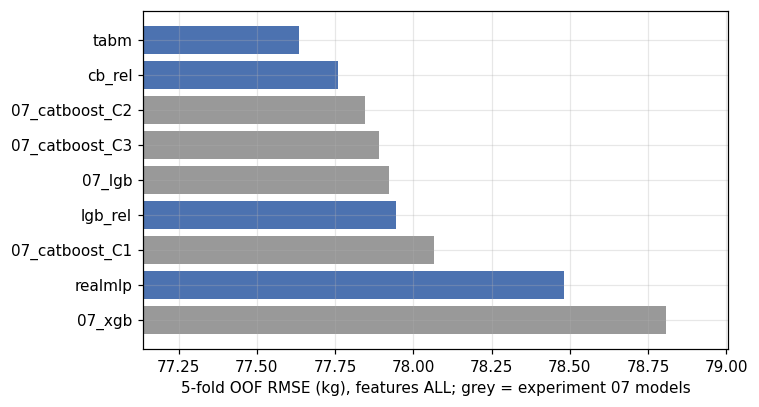

三种堆叠方式（五折嵌套，诚实分数）：


,nested_oof_rmse,fold1,fold2,fold3,fold4,fold5
global_nnls,77.013,77.094,77.201,77.318,77.082,76.365
segment_nnls,77.017,77.098,77.172,77.335,77.112,76.364
residual_meta,77.098,77.173,77.266,77.385,77.199,76.462


In [10]:
def show_zoo():
    directory = ARTIFACTS / '03_model_selection' / 'model_zoo'
    models = read_summary(directory / 'summary_models.csv')
    print('单独的五折 OOF RMSE，以及加入实验 07 三模型融合后的变化（07_ 开头的是实验 07 的模型）：')
    show(models, ['oof_rmse', 'corr_with_07_blend', 'blend_with_07', 'delta_vs_07_blend', 'folds_better'])
    if models is not None:
        ordered = models.sort_values('oof_rmse', ascending=False)
        fig, ax = plt.subplots(figsize=(7, 3.8))
        ax.barh(range(len(ordered)), ordered['oof_rmse'],
                color=['#999999' if n.startswith('07_') else '#4c72b0' for n in ordered.index])
        ax.set_yticks(range(len(ordered)))
        ax.set_yticklabels(ordered.index.tolist())
        ax.set_xlim(ordered['oof_rmse'].min() - 0.5, ordered['oof_rmse'].max() + 0.2)
        ax.set_xlabel('5-fold OOF RMSE (kg), features ALL; grey = experiment 07 models')
        plt.tight_layout()
        plt.show()
    print('三种堆叠方式（五折嵌套，诚实分数）：')
    show(read_summary(directory / 'summary_stacking.csv'))


show_zoo()

**结论**：
- **TabM 77.636 是当时最好的单模型**，加入实验 07 融合 −0.15（5/5 折）；cb_rel −0.06，RealMLP −0.07（但每折 15 分钟），lgb_rel −0.04。
- 三种堆叠方式中全局 NNLS 最好。最终集成用全局 NNLS（非负权重，不加截距）。

## 4. 目标变量工程（实验 14）

cb_rel 用的 DOTS 系数之外，再试两种力量公式作为目标（预测后乘回 kg，按系数² 加权）：
- **异速生长**：总成绩 ÷ 体重^(2/3)；
- **IPF GL 系数**：按性别 × 是否装备分别取系数，Raw 与 Wraps 算无装备。

训练代码在 02 的第四轮训练开关里。

In [11]:
print('目标变量工程：R3 特征，种子 42 五折；增益为加入 LightGBM + XGBoost + cb_rel 融合后的嵌套 ΔRMSE')
show(read_summary(ARTIFACTS / '02_feature_engineering' / 'round4' / 'summary_target_engineering.csv'))

目标变量工程：R3 特征，种子 42 五折；增益为加入 LightGBM + XGBoost + cb_rel 融合后的嵌套 ΔRMSE


,oof,corr_with_cb_rel,blend_delta_nested,folds_better
model,,,,
lgb,77.709,NaN,NaN,NaN
xgb,78.458,NaN,NaN,NaN
cb_rel,77.160,NaN,NaN,NaN
cb_allo,77.327,0.997,-0.043,5.0
cb_gl,77.162,0.998,-0.076,5.0


**结论**：**IPF GL 目标的 CatBoost（`cb_gl`）单独 77.162**，与 cb_rel（77.160）一样强，两者相关 0.9975，加入三模型融合 −0.076（5/5 折），进入最终集成。异速生长 −0.043。

## 5. 其他模型大比较（实验 13）

所有模型用同样的最终特征（LightGBM / TabM 那一套，57 列）和种子 42 的五折。比较两件事：
- 单独的分数，与实验 11 中最终模型的种子 42 直接可比；
- 加入实验 11 的 6 模型融合后，五折嵌套 NNLS 的变化和权重。融合只看「错误是否不同」，单独弱的模型也可能有用。

MLP-PLR 与 ResNet 因为缺少依赖包 skorch 没有跑成。

In [12]:
if TRAIN['model_compare']:
    ensure_training_env()
    # 实验 13 的设置（结果目录：原 artifacts/model_compare_v1）
    OUTPUT_DIR = ARTIFACTS / '03_model_selection' / 'model_compare'
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    SEEDS = [42, 7, 2024]                      # 每个种子：不同的五折划分、内层早停划分和模型随机性
    FINAL_MODELS = ['lgb', 'xgb', 'lgb_rel', 'catboost', 'cb_rel', 'tabm']   # 每折内的运行顺序：快的先跑
    FULL_REFIT = True                          # 树模型在全部训练行上重训
    REFIT_FACTOR = 1.2                         # 全量重训轮数 = CV 平均最佳轮数 × 1.2（数据多约 39%）

    PREV_DIR = ARTIFACTS / '04_final_model' / 'v1_six_models'     # 实验 11 的结果
    BOOST_DIR = ARTIFACTS / '04_final_model' / 'v2_more_seeds'    # 实验 12 的结果
    PREV_SEEDS = [42, 7, 2024]
    COMPARE = ['ridge', 'hgb', 'et', 'rf', 'tabpfn', 'mlp_plr', 'resnet', 'ebm']   # 运行顺序：快的先跑
    OPTIONAL = []                         # 想多试可以加 'ftt'（很慢）、'tabr'（需要 faiss）
    TABPFN_CONTEXT_ROWS = 10000           # TabPFN v2 的预训练上限是 10,000 行
    ADD_DELTA = -0.02                     # 加入融合的门槛：嵌套 ΔRMSE ≤ −0.02 且 ≥ 4/5 折
    TABPFN_TOKEN = os.environ.get('TABPFN_TOKEN')
    if not TABPFN_TOKEN and drive is not None:
        try:
            from google.colab import userdata
            TABPFN_TOKEN = userdata.get('TABPFN_TOKEN')
        except Exception:
            TABPFN_TOKEN = None
    if TABPFN_TOKEN:
        os.environ['TABPFN_TOKEN'] = TABPFN_TOKEN
    print('TabPFN：', '最新版（已提供 TABPFN_TOKEN）' if TABPFN_TOKEN else 'v2（无需登录）')
    if not (PREV_DIR / 'summary_weights.csv').is_file():
        raise FileNotFoundError(f'缺少实验 11 的结果：{PREV_DIR}')
    # ---- 最终特征：10 的 ALL3（三个块都达标）----
    _FRAMES3.clear()
    VARIANTS3['ALL3'] = ['H2', 'E', 'PM']
    FAMILY = {'lgb': 'lgb', 'lgb_rel': 'lgb', 'tabm': 'lgb', 'xgb': 'xgb', 'catboost': 'catboost', 'cb_rel': 'catboost'}
    FRAMES = {m: frames3('ALL3', FAMILY[m]) for m in FINAL_MODELS}
    for m, (Xtr_m, Xte_m, cats_m) in FRAMES.items():
        print(f'{m:9s} {Xtr_m.shape[1]} 列（{len(cats_m)} 个类别列），块：{blocks_for("ALL3", FAMILY[m])}')


    LGB_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                      colsample_bytree=0.8, cat_smooth=20, verbose=-1)
    XGB_PARAMS = dict(learning_rate=0.03, max_depth=8, min_child_weight=10.0, subsample=0.8, colsample_bytree=0.7,
                      reg_lambda=1.0, tree_method='hist', device='cuda', enable_categorical=True,
                      max_cat_to_onehot=1, eval_metric='rmse')
    CB_PARAMS = dict(learning_rate=0.05, depth=8, l2_leaf_reg=10.0, bootstrap_type='Bernoulli', subsample=0.8,
                     border_count=128)
    TABM_PARAMS = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0, num_emb_type='pwl')
    TABM_FALLBACK = dict(device='cuda', n_cv=1, n_refit=0, verbosity=0)
    PATIENCE = {'lgb': 200, 'lgb_rel': 200, 'xgb': 200, 'catboost': 300, 'cb_rel': 300}
    GBDT = [m for m in FINAL_MODELS if m != 'tabm']

    SCALE = dots_scale(train['Sex'], train['BodyweightKg'])           # dots_scale 来自 09 的特征单元
    SCALE_TEST = dots_scale(test['Sex'], test['BodyweightKg'])
    require(min(SCALE.min(), SCALE_TEST.min()) > 0.3, 'DOTS 系数异常')

    X_NN, XT_NN, CATS_NN = FRAMES['tabm']
    NUM_NN = [c for c in X_NN.columns if c not in CATS_NN]
    NAN_NN = [c for c in NUM_NN if X_NN[c].isna().any() or XT_NN[c].isna().any()]


    def target_and_weight(model, rows):
        if model.endswith('_rel'):
            return y[rows] / SCALE[rows], SCALE[rows] ** 2       # 相对力量误差 × scale = kg 误差
        return y[rows], None


    def gbdt_fit(model, seed, Xa, ya, wa, Xs=None, ys=None, ws=None, rounds=MAX_ROUNDS):
        """Xs 为 None 时不早停（全量重训）。返回 (模型, 最佳轮数)。"""
        cats = FRAMES[model][2]
        if model in ('lgb', 'lgb_rel'):
            m = lgb.LGBMRegressor(n_estimators=rounds, random_state=seed, n_jobs=-1, **LGB_PARAMS)
            if Xs is None:
                m.fit(Xa, ya, sample_weight=wa)
                return m, rounds
            m.fit(Xa, ya, sample_weight=wa, eval_set=[(Xs, ys)], eval_sample_weight=None if ws is None else [ws],
                  callbacks=[lgb.early_stopping(PATIENCE[model], verbose=False)])
            return m, int(m.best_iteration_ or rounds)
        if model == 'xgb':
            if Xs is None:
                m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, **XGB_PARAMS)
                m.fit(Xa, ya, verbose=False)
                return m, rounds
            m = xgb.XGBRegressor(n_estimators=rounds, random_state=seed, early_stopping_rounds=PATIENCE['xgb'],
                                 **XGB_PARAMS)
            m.fit(Xa, ya, eval_set=[(Xs, ys)], verbose=False)
            return m, int(m.best_iteration) + 1
        common = dict(iterations=rounds, loss_function='RMSE', eval_metric='RMSE', random_seed=seed, verbose=0,
                      task_type='GPU', devices='0', allow_writing_files=False, **CB_PARAMS)
        if Xs is None:
            m = catboost.CatBoostRegressor(**common)
            m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa))
            return m, rounds
        m = catboost.CatBoostRegressor(od_type='Iter', od_wait=PATIENCE[model], **common)
        m.fit(catboost.Pool(Xa, ya, cat_features=cats, weight=wa),
              eval_set=catboost.Pool(Xs, ys, cat_features=cats, weight=ws), use_best_model=True)
        return m, int(m.get_best_iteration()) + 1


    def gbdt_predict(model, m, best, X):
        if model in ('lgb', 'lgb_rel'):
            return m.predict(X, num_iteration=best)
        if model == 'xgb':
            return m.predict(X, iteration_range=(0, best))
        return m.predict(X)


    def nn_frames(*frames):
        """数值缺失用第一个表（外层训练部分）的中位数填补并加缺失标记；类别保持 category。"""
        median = frames[0][NUM_NN].median()
        out = []
        for frame in frames:
            z = frame.copy()
            for c in NAN_NN:
                z[f'{c}_isna'] = z[c].isna().astype('float64')
            z[NUM_NN] = z[NUM_NN].fillna(median).fillna(0.0)
            out.append(z.reset_index(drop=True))
        return out


    def tabm_fit_predict(seed, a, s, v, Xt, overrides=None):
        require(TabM_D_Regressor is not None, f'pytabkit 不可用：{PYTABKIT_ERROR}')
        params = dict(TABM_PARAMS, random_state=seed, **(overrides or {}))
        unknown = set(params) - set(inspect.signature(TabM_D_Regressor.__init__).parameters)
        require(not unknown, f'TabM 不支持参数 {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_NN.iloc[a], X_NN.iloc[s], X_NN.iloc[v], Xt)
        mu, sd = y[a].mean(), y[a].std()
        m = TabM_D_Regressor(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CATS_NN])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_fold(model, seed, a, s, v, test_rows=None, rounds=MAX_ROUNDS, overrides=None):
        """a / s / v：内层拟合 / 内层早停 / 外层验证 的训练行号。返回 (验证预测, 测试预测, 最佳轮数或 None)。"""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        if model == 'tabm':
            p_val, p_test = tabm_fit_predict(seed, a, s, v, Xt, overrides)
            return p_val, p_test, None
        ya, wa = target_and_weight(model, a)
        ys, ws = target_and_weight(model, s)
        if wa is not None:
            norm = wa.mean()
            wa, ws = wa / norm, ws / norm
        m, best = gbdt_fit(model, seed, Xtr.iloc[a], ya, wa, Xtr.iloc[s], ys, ws, rounds)
        p_val, p_test = gbdt_predict(model, m, best, Xtr.iloc[v]), gbdt_predict(model, m, best, Xt)
        if model.endswith('_rel'):
            p_val, p_test = np.asarray(p_val) * SCALE[v], np.asarray(p_test) * scale_t
        return np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64'), best


    def fit_full(model, seed, rounds, test_rows=None):
        """全部训练行、固定轮数、不早停。返回测试预测。"""
        Xtr, Xte, _ = FRAMES[model]
        Xt = Xte if test_rows is None else Xte.iloc[test_rows]
        scale_t = SCALE_TEST if test_rows is None else SCALE_TEST[test_rows]
        rows = np.arange(n_train)
        ya, wa = target_and_weight(model, rows)
        if wa is not None:
            wa = wa / wa.mean()
        m, _ = gbdt_fit(model, seed, Xtr, ya, wa, rounds=rounds)
        p_test = gbdt_predict(model, m, rounds, Xt)
        if model.endswith('_rel'):
            p_test = np.asarray(p_test) * scale_t
        return np.asarray(p_test, dtype='float64')


    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor, RandomForestRegressor
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import Ridge
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

    X_BASE, XT_BASE, CATS = FRAMES['lgb']            # R2 + H2 + E，类别为 category（与 TabM 相同）
    NUMS = [c for c in X_BASE.columns if c not in CATS]
    PYTABKIT_CLASSES = {'mlp_plr': 'MLP_PLR_D_Regressor', 'resnet': 'Resnet_RTDL_D_Regressor',
                        'ftt': 'FTT_D_Regressor', 'tabr': 'TabR_S_D_Regressor'}


    def numeric_with_codes(enc, X, fill=None):
        num = X[NUMS].to_numpy(dtype='float64')
        if fill is not None:
            num = np.where(np.isnan(num), fill, num)
        return np.hstack([num, enc.transform(X[CATS])])


    def fit_ridge(seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        pre = ColumnTransformer([
            ('num', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), NUMS),
            ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20), CATS)])
        model = make_pipeline(pre, Ridge(alpha=10.0)).fit(X_BASE.iloc[rows], y[rows])
        return model.predict(X_BASE.iloc[v]), model.predict(Xt)


    def fit_hgb(seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan, encoded_missing_value=np.nan,
                             max_categories=250).fit(X_BASE.iloc[rows][CATS])
        mask = [False] * len(NUMS) + [True] * len(CATS)
        model = HistGradientBoostingRegressor(
            categorical_features=mask, learning_rate=0.05, max_iter=20 if small else 3000, max_leaf_nodes=63,
            min_samples_leaf=40, l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
            n_iter_no_change=100, random_state=seed)
        model.fit(numeric_with_codes(enc, X_BASE.iloc[rows]), y[rows])           # 内部留 10% 早停
        return model.predict(numeric_with_codes(enc, X_BASE.iloc[v])), model.predict(numeric_with_codes(enc, Xt))


    def fit_forest(kind, seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(X_BASE.iloc[rows][CATS])
        common = dict(n_estimators=10 if small else 200, min_samples_leaf=5, n_jobs=-1, random_state=seed)
        model = (RandomForestRegressor(max_features=0.3, max_samples=0.5, **common) if kind == 'rf'
                 else ExtraTreesRegressor(max_features=0.5, **common))
        model.fit(numeric_with_codes(enc, X_BASE.iloc[rows], fill=-999.0), y[rows])
        return (model.predict(numeric_with_codes(enc, X_BASE.iloc[v], fill=-999.0)),
                model.predict(numeric_with_codes(enc, Xt, fill=-999.0)))


    def fit_ebm(seed, a, s, v, Xt, small=False):
        from interpret.glassbox import ExplainableBoostingRegressor
        rows = np.concatenate([a, s])
        model = ExplainableBoostingRegressor(interactions=0 if small else 5, outer_bags=1 if small else 2,
                                             max_rounds=50 if small else 5000, n_jobs=-1, random_state=seed)
        model.fit(X_BASE.iloc[rows], y[rows])                                   # 内部留出验证集早停
        return np.asarray(model.predict(X_BASE.iloc[v])), np.asarray(model.predict(Xt))


    def make_tabpfn():
        from tabpfn import TabPFNRegressor
        if TABPFN_TOKEN:
            return TabPFNRegressor(device='cuda', ignore_pretraining_limits=True)
        from tabpfn.constants import ModelVersion
        return TabPFNRegressor.create_default_for_version(ModelVersion.V2)


    def fit_tabpfn(seed, a, s, v, Xt, small=False):
        rows = np.concatenate([a, s])
        context = np.random.default_rng(seed).choice(rows, size=min(500 if small else TABPFN_CONTEXT_ROWS, len(rows)),
                                                     replace=False)
        enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan,
                             encoded_missing_value=np.nan).fit(X_BASE.iloc[context][CATS])
        model = make_tabpfn()
        model.fit(numeric_with_codes(enc, X_BASE.iloc[context]), y[context])
        p_val = np.asarray(model.predict(numeric_with_codes(enc, X_BASE.iloc[v])), dtype='float64')
        p_test = np.asarray(model.predict(numeric_with_codes(enc, Xt)), dtype='float64')
        del model
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_pytabkit(name, seed, a, s, v, Xt, small=False):
        if name == 'tabr':
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faiss-cpu'], check=False)
        import pytabkit
        cls = getattr(pytabkit, PYTABKIT_CLASSES[name])
        params = dict(device='cuda', random_state=seed, n_cv=1, n_refit=0, verbosity=0)
        if small:
            params['max_epochs'] = 2
        unknown = set(params) - set(inspect.signature(cls.__init__).parameters)
        require(not unknown, f'{name} 不支持参数 {sorted(unknown)}')
        Za, Zs, Zv, Zt = nn_frames(X_NN.iloc[a], X_NN.iloc[s], X_NN.iloc[v], Xt)    # 与 TabM 相同的填补
        mu, sd = y[a].mean(), y[a].std()
        m = cls(**params)
        m.fit(Za, (y[a] - mu) / sd, Zs, (y[s] - mu) / sd, cat_col_names=[c for c in Za.columns if c in CATS_NN])
        p_val = np.asarray(m.predict(Zv), dtype='float64').reshape(-1) * sd + mu
        p_test = np.asarray(m.predict(Zt), dtype='float64').reshape(-1) * sd + mu
        del m
        gc.collect()
        torch.cuda.empty_cache()
        return p_val, p_test


    def fit_new(name, seed, a, s, v, Xt, small=False):
        if name == 'ridge':
            return fit_ridge(seed, a, s, v, Xt, small)
        if name == 'hgb':
            return fit_hgb(seed, a, s, v, Xt, small)
        if name in ('rf', 'et'):
            return fit_forest(name, seed, a, s, v, Xt, small)
        if name == 'ebm':
            return fit_ebm(seed, a, s, v, Xt, small)
        if name == 'tabpfn':
            return fit_tabpfn(seed, a, s, v, Xt, small)
        return fit_pytabkit(name, seed, a, s, v, Xt, small)


    def save_result(stem, arrays, info):
        np.savez(OUTPUT_DIR / f'{stem}.npz', **arrays)
        info = {**info, 'gpu': GPU_NAME, 'versions': VERSIONS, 'finished_at_utc': datetime.now(timezone.utc).isoformat()}
        (OUTPUT_DIR / f'{stem}.json').write_text(json.dumps(info, ensure_ascii=False, indent=1), encoding='utf-8')
        return info


    # 预检：每个模型在 3,000 行上用很小的预算跑一次（几秒到一两分钟），失败的自动跳过
    rng = np.random.default_rng(SEED)
    probe = rng.choice(n_train, 3000, replace=False)
    pa, ps, pv = probe[:2000], probe[2000:2500], probe[2500:]
    failed = {}
    for name in COMPARE + OPTIONAL:
        started = time.perf_counter()
        try:
            p_val, p_test = fit_new(name, SEED, pa, ps, pv, XT_BASE.iloc[:300], small=True)
            p_val, p_test = np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64')
            require(len(p_val) == len(pv) and len(p_test) == 300, '预测长度不符')
            require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), '预测含非有限值')
            print(f'预检通过：{name:8s} RMSE（小预算）{rmse(y[pv], p_val):.1f}，用时 {time.perf_counter() - started:.0f}s')
        except Exception as exc:
            failed[name] = repr(exc)
            print(f'预检失败，跳过：{name} → {exc!r}')
    RUN_NEW = [n for n in COMPARE + OPTIONAL if n not in failed]
    print('将运行：', RUN_NEW)


    def run_new(name, fold):
        stem = f'{name}__s{SEED}__fold{fold}'
        json_path, npz_path = OUTPUT_DIR / f'{stem}.json', OUTPUT_DIR / f'{stem}.npz'
        if json_path.is_file() and npz_path.is_file():
            return json.loads(json_path.read_text(encoding='utf-8')), 'cache'
        fit_idx, valid_idx = np.flatnonzero(FOLD_IDS != fold), np.flatnonzero(FOLD_IDS == fold)
        inner_fit, inner_stop = train_test_split(fit_idx, test_size=INNER_STOP_FRACTION, random_state=SEED)  # = 11
        started = time.perf_counter()
        p_val, p_test = fit_new(name, SEED, inner_fit, inner_stop, valid_idx, XT_BASE)
        p_val, p_test = np.asarray(p_val, dtype='float64'), np.asarray(p_test, dtype='float64')
        require(np.isfinite(p_val).all() and np.isfinite(p_test).all(), f'{stem} 预测含非有限值')
        info = save_result(stem, {'valid_idx': valid_idx, 'val': p_val, 'test': p_test},
                           {'model': name, 'fold': fold, 'rmse': rmse(y[valid_idx], p_val),
                            'seconds': time.perf_counter() - started})
        return info, f'{info["seconds"]:.0f}s'


    for name in RUN_NEW:
        started = time.perf_counter()
        try:
            for fold in range(1, N_FOLDS + 1):
                info, how = run_new(name, fold)
                print(f'{name:8s} fold {fold}  RMSE {info["rmse"]:.3f}  ({how})')
            print(f'—— {name} 完成，本次运行用时 {(time.perf_counter() - started) / 60:.1f} 分钟')
        except Exception as exc:
            print(f'!! {name} 运行出错，跳过剩下的折：{exc!r}')


    def load_folds(directory, stem_prefix):
        oof, test_pred = np.full(n_train, np.nan), np.zeros(len(test))
        for fold in range(1, N_FOLDS + 1):
            path = directory / f'{stem_prefix}__fold{fold}.npz'
            if not path.is_file():
                return None
            saved = np.load(path)
            oof[saved['valid_idx']] = saved['val']
            test_pred += saved['test'] / N_FOLDS
        return oof, test_pred


    def fold_rmse(pred):
        return np.array([rmse(y[FOLD_IDS == k], pred[FOLD_IDS == k]) for k in range(1, N_FOLDS + 1)])


    def nested_nnls(P):
        out = np.zeros(n_train)
        for k in range(1, N_FOLDS + 1):
            fit, va = FOLD_IDS != k, FOLD_IDS == k
            w, _ = nnls(P[fit], y[fit])
            out[va] = P[va] @ w
        return out


    # 11 的 6 个模型：种子 42 的 OOF（单独比较用）、三种子平均 OOF（融合用）、最好的测试预测
    BASE = {}
    for model in FINAL_MODELS:
        per_seed = {s: load_folds(PREV_DIR, f'{model}__s{s}') for s in PREV_SEEDS}
        require(all(v is not None for v in per_seed.values()), f'11 缺少 {model} 的结果')
        fulls = [np.load(p)['test'] for d in (PREV_DIR, BOOST_DIR) if d.is_dir() for p in sorted(d.glob(f'{model}__s*__full.npz'))]
        near = [np.load(p)['test'] for p in sorted(BOOST_DIR.glob('tabm__s*__nearfull.npz'))] if BOOST_DIR.is_dir() else []
        fold_avg = np.mean([t for _, t in per_seed.values()], axis=0)
        best_test = np.mean(fulls, axis=0) if fulls else (np.mean(near, axis=0) if (model == 'tabm' and near) else fold_avg)
        BASE[model] = {'oof42': per_seed[42][0], 'oof': np.mean([o for o, _ in per_seed.values()], axis=0),
                       'test': best_test}
    NEW = {}
    for name in COMPARE + OPTIONAL:
        loaded = load_folds(OUTPUT_DIR, f'{name}__s{SEED}')
        if loaded is not None:
            NEW[name] = {'oof42': loaded[0], 'oof': loaded[0], 'test': loaded[1]}

    base_names = list(BASE)
    P_base = np.column_stack([BASE[m]['oof'] for m in base_names])
    base_nested = nested_nnls(P_base)
    base_folds = fold_rmse(base_nested)
    rows = []
    for name, item in {**BASE, **NEW}.items():
        row = {'model': name, '来源': '11' if name in BASE else '13', 'oof_seed42': rmse(y, item['oof42']),
               'corr_with_blend': float(np.corrcoef(item['oof42'], base_nested)[0, 1])}
        if name in NEW:
            P = np.column_stack([P_base, item['oof']])
            nested = nested_nnls(P)
            delta = fold_rmse(nested) - base_folds
            w, _ = nnls(P, y)
            row.update({'blend_nested': rmse(y, nested), 'delta_vs_blend': rmse(y, nested) - rmse(y, base_nested),
                        'folds_better': int((delta < 0).sum()), 'weight_in_blend': float(w[-1])})
        rows.append(row)
    compare = pd.DataFrame(rows).set_index('model').sort_values('oof_seed42')
    print(f'11 的 6 模型融合（嵌套）：{rmse(y, base_nested):.3f}')
    display(compare.round(3))
    compare.to_csv(OUTPUT_DIR / 'summary_compare.csv')
    seconds = {}
    for p in OUTPUT_DIR.glob('*__fold*.json'):
        info = json.loads(p.read_text(encoding='utf-8'))
        seconds.setdefault(info['model'], []).append(info['seconds'])
    print('每折平均用时（秒）：', {k: round(float(np.mean(v))) for k, v in seconds.items()})

    KEEP_NEW = [n for n in NEW if compare.loc[n, 'delta_vs_blend'] <= ADD_DELTA and compare.loc[n, 'folds_better'] >= 4]
    print('达到加入门槛的新模型：', KEEP_NEW or '无')


    if KEEP_NEW:
        names = base_names + KEEP_NEW
        ITEMS = {**BASE, **{n: NEW[n] for n in KEEP_NEW}}
        P_all = np.column_stack([ITEMS[n]['oof'] for n in names])
        WEIGHTS_PLUS, _ = nnls(P_all, y)
        NESTED = nested_nnls(P_all)
        BLEND_TEST = {'v3_plus': np.column_stack([ITEMS[n]['test'] for n in names]) @ WEIGHTS_PLUS}
        print('权重：', dict(zip(names, WEIGHTS_PLUS.round(3))))
        print(f'嵌套融合：{rmse(y, base_nested):.3f} → {rmse(y, NESTED):.3f}')
    else:
        NESTED, BLEND_TEST = None, None
        print('没有新模型达到门槛，最终提交保持 11 / 12 的版本。')


    if BLEND_TEST is not None:
        CORE = CORE9


        def row_keys(frame, columns):
            return pd.util.hash_pandas_object(frame[columns], index=False).to_numpy()


        def mate_stats(train_keys, query_keys=None):
            table = pd.DataFrame({'k': train_keys, 'y': y}).groupby('k')['y'].agg(['sum', 'count'])
            if query_keys is None:                      # 训练行：留一
                keys = pd.Series(train_keys)
                n = keys.map(table['count']).to_numpy() - 1
                s = keys.map(table['sum']).to_numpy() - y
            else:                                       # 测试行：全部训练行
                keys = pd.Series(query_keys)
                n = keys.map(table['count']).fillna(0).to_numpy()
                s = keys.map(table['sum']).fillna(0).to_numpy()
            return n, np.where(n > 0, s / np.maximum(n, 1), np.nan)


        def twins(query_exact=None, query_core=None):
            n_ex, m_ex = mate_stats(row_keys(train, RAW_FEATURES), query_exact)
            n_co, m_co = mate_stats(row_keys(train, CORE), query_core)
            level = np.select([n_ex > 0, n_co > 0], ['exact', 'core'], default='none')
            return level, np.where(level == 'exact', m_ex, m_co)


        def fit_alpha(mask, pred, mate):
            d = mate[mask] - pred[mask]
            denom = float(np.sum(d * d))
            return float(np.clip(np.sum((y[mask] - pred[mask]) * d) / denom, 0, 1)) if denom > 0 else 0.0


        def apply_twins(pred, mate, level, alphas):
            out = pred.copy()
            for lv, a in alphas.items():
                m = level == lv
                out[m] = pred[m] + a * (mate[m] - pred[m])
            return out


        LEVEL, MATE = twins()
        T_LEVEL, T_MATE = twins(row_keys(test, RAW_FEATURES), row_keys(test, CORE))
        HALF = (pd.util.hash_pandas_object(train[['Sex', 'Country', 'State']], index=False).to_numpy() % 2).astype(int)
        TR, TE = train.reset_index(drop=True), test.reset_index(drop=True)


        def text_key(frame, columns):
            out = frame[columns[0]].astype(str)
            for c in columns[1:]:
                out = out + '|' + frame[c].astype(str)
            return out


        BY_TR = np.floor(TR['MeetYear'] - TR['Age'] + 1e-9).astype(int)
        BY_TE = np.floor(TE['MeetYear'] - TE['Age'] + 1e-9).astype(int)
        YR_TR, YR_TE = TR['MeetYear'].astype(int), TE['MeetYear'].astype(int)
        PREFIX = {'A0': ['Sex', 'Country', 'State'], 'A1': ['Sex', 'Country', 'State', 'Federation'],
                  'A2': ['Sex', 'Country', 'State', 'Federation', 'Equipment'],
                  'A3': ['Sex', 'Country', 'State', 'Federation', 'Equipment', 'WeightClassKg']}
        SHRINK = {'A0': 5.0, 'A1': 5.0, 'A2': 3.0, 'A3': 2.0}
        PFX_TR = {k: text_key(TR, c) for k, c in PREFIX.items()}
        PFX_TE = {k: text_key(TE, c) for k, c in PREFIX.items()}
        MEET_COLS = ['Federation', 'MeetYear', 'MeetCountry', 'MeetState', 'Sex', 'Equipment']
        MEET_TR, MEET_TE = text_key(TR, MEET_COLS), text_key(TE, MEET_COLS)
        VALID_TR = (TR['Country'] != 'Unknown').to_numpy(dtype='float64')
        VALID_TE = (TE['Country'] != 'Unknown').to_numpy(dtype='float64')


        def sums(keys, values):
            table = pd.DataFrame({'k': keys.to_numpy(), 'v': values}).groupby('k')['v'].agg(['sum', 'count'])
            return table['sum'], table['count']


        def look(table, keys):
            s, n = table
            return keys.map(s).fillna(0).to_numpy(dtype='float64'), keys.map(n).fillna(0).to_numpy(dtype='float64')


        def f_exact(k, r):
            ktr, kte = PFX_TR[k] + '|' + BY_TR.astype(str), PFX_TE[k] + '|' + BY_TE.astype(str)
            table = sums(ktr, r)
            s, n = look(table, ktr)
            st, nt = look(table, kte)
            return (s - r) / (n - 1 + SHRINK[k]), st / (nt + SHRINK[k])


        def f_fuzzy(k, r):
            table = sums(PFX_TR[k] + '|' + BY_TR.astype(str), r)
            s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
            for d in (-1, 0, 1):
                a, b = look(table, PFX_TR[k] + '|' + (BY_TR + d).astype(str))
                s, n = s + a, n + b
                a, b = look(table, PFX_TE[k] + '|' + (BY_TE + d).astype(str))
                st, nt = st + a, nt + b
            return (s - r) / (n - 1 + SHRINK[k]), st / (nt + SHRINK[k])


        def f_decay(k, r, tau=3.0, max_gap=8):
            base_tr = PFX_TR[k] + '|' + BY_TR.astype(str) + '|'
            base_te = PFX_TE[k] + '|' + BY_TE.astype(str) + '|'
            table = sums(base_tr + YR_TR.astype(str), r)
            s, n, st, nt = np.zeros(n_train), np.zeros(n_train), np.zeros(len(TE)), np.zeros(len(TE))
            for d in range(-max_gap, max_gap + 1):
                w = float(np.exp(-abs(d) / tau))
                a, b = look(table, base_tr + (YR_TR + d).astype(str))
                s, n = s + w * a, n + w * b
                a, b = look(table, base_te + (YR_TE + d).astype(str))
                st, nt = st + w * a, nt + w * b
            return (s - r) / (n - 1 + SHRINK[k]), st / (nt + SHRINK[k])     # d = 0 时自己权重为 1，已扣除


        def f_meet(r, lam=20.0):
            table = sums(MEET_TR, r)
            s, n = look(table, MEET_TR)
            st, nt = look(table, MEET_TE)
            return (s - r) / (n - 1 + lam), st / (nt + lam)


        def s3_features(r):
            cols_tr, cols_te = [], []
            for builder in (f_exact, f_fuzzy, f_decay):
                for k in PREFIX:
                    a, b = builder(k, r)
                    cols_tr.append(a * VALID_TR)
                    cols_te.append(b * VALID_TE)
            a, b = f_meet(r)
            cols_tr.append(a)
            cols_te.append(b)
            return np.column_stack(cols_tr), np.column_stack(cols_te)


        # 第二层只依赖训练行的 OOF（嵌套融合），对三种测试预测使用同一组 alpha / 系数
        alphas = {lv: fit_alpha(LEVEL == lv, NESTED, MATE) for lv in ['exact', 'core']}
        p1 = apply_twins(NESTED, MATE, LEVEL, alphas)
        p1_cf = NESTED.copy()
        for h in (0, 1):
            a_h = {lv: fit_alpha((HALF != h) & (LEVEL == lv), NESTED, MATE) for lv in ['exact', 'core']}
            m = HALF == h
            p1_cf[m] = apply_twins(NESTED[m], MATE[m], LEVEL[m], a_h)
        r1 = y - p1
        F, FT = s3_features(r1)
        p2_cf = p1_cf.copy()
        for h in (0, 1):
            fit, m = HALF != h, HALF == h
            beta_h = np.linalg.lstsq(F[fit], r1[fit], rcond=None)[0]
            p2_cf[m] = p1_cf[m] + F[m] @ beta_h
        BETA = np.linalg.lstsq(F, r1, rcond=None)[0]
        STAGE2_ADJ = FT @ BETA
        stage_table = pd.DataFrame([{'step': '融合（嵌套）', 'oof_rmse': rmse(y, NESTED)},
                                    {'step': '+ 双胞胎（交叉拟合）', 'oof_rmse': rmse(y, p1_cf)},
                                    {'step': '+ S3 平滑（交叉拟合）', 'oof_rmse': rmse(y, p2_cf)}]).set_index('step')
        display(stage_table.round(3))
        stage_table.to_csv(OUTPUT_DIR / 'summary_stage2.csv')
        print('alpha：', {k: round(v, 3) for k, v in alphas.items()}, '｜测试中有双胞胎的行：', int((T_LEVEL != 'none').sum()),
              '｜S3 平均调整幅度：', round(float(np.abs(STAGE2_ADJ).mean()), 2), 'kg')

        for kind, pred in BLEND_TEST.items():
            final = apply_twins(pred, T_MATE, T_LEVEL, alphas) + STAGE2_ADJ
            for stage, values in [('base', pred), ('final', final)]:
                path = OUTPUT_DIR / f'submission_final_{kind}_{stage}.csv'
                pd.DataFrame({'id': test['id'], TARGET: np.clip(values, 0, None)}).to_csv(path, index=False)
                print('写出', path.name)
        np.save(OUTPUT_DIR / 'oof_nested_blend.npy', NESTED)
        np.save(OUTPUT_DIR / 'oof_final_crossfit.npy', p2_cf)
    print('完成。')
else:
    print("训练开关关闭（TRAIN['model_compare'] = False）：本节只读取 artifacts/ 中已保存的结果。")

训练开关关闭（TRAIN['model_compare'] = False）：本节只读取 artifacts/ 中已保存的结果。


,来源,oof_seed42,corr_with_blend,blend_nested,delta_vs_blend,folds_better,weight_in_blend
model,,,,,,,
cb_rel,11,77.167,0.997,NaN,NaN,NaN,NaN
tabm,11,77.493,0.996,NaN,NaN,NaN,NaN
catboost,11,77.497,0.996,NaN,NaN,NaN,NaN
lgb_rel,11,77.646,0.996,NaN,NaN,NaN,NaN
lgb,11,77.709,0.995,NaN,NaN,NaN,NaN
hgb,13,77.881,0.994,76.361,-0.034,5.0,0.147
xgb,11,78.458,0.993,NaN,NaN,NaN,NaN
et,13,81.054,0.985,76.395,0.000,0.0,0.000
ebm,13,81.448,0.985,76.395,0.000,0.0,0.000


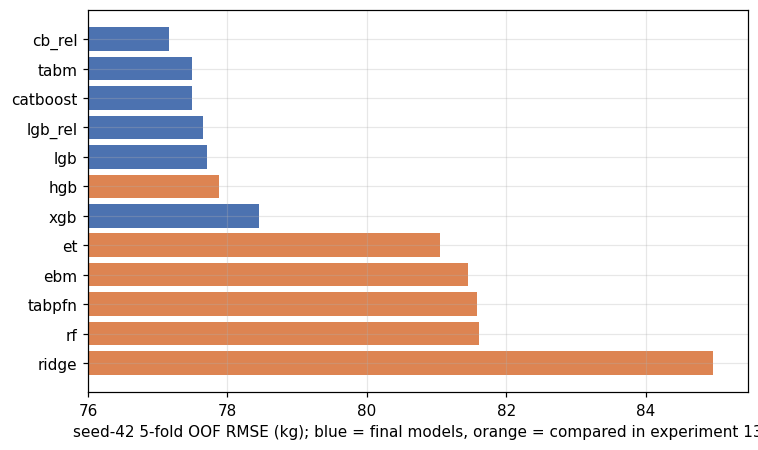

In [13]:
def show_compare():
    compare = read_summary(ARTIFACTS / '03_model_selection' / 'model_compare' / 'summary_compare.csv')
    show(compare, ['来源', 'oof_seed42', 'corr_with_blend', 'blend_nested', 'delta_vs_blend', 'folds_better',
                   'weight_in_blend'])
    if compare is not None:
        ordered = compare.sort_values('oof_seed42', ascending=False)
        fig, ax = plt.subplots(figsize=(7, 4.2))
        ax.barh(range(len(ordered)), ordered['oof_seed42'],
                color=['#4c72b0' if s == 11 or str(s) == '11' else '#dd8452' for s in ordered['来源']])
        ax.set_yticks(range(len(ordered)))
        ax.set_yticklabels(ordered.index.tolist())
        ax.set_xlim(76, ordered['oof_seed42'].max() + 0.5)
        ax.set_xlabel('seed-42 5-fold OOF RMSE (kg); blue = final models, orange = compared in experiment 13')
        plt.tight_layout()
        plt.show()


show_compare()

**结论**：
- 梯度提升树（CatBoost、LightGBM、XGBoost、sklearn HGB）和 TabM 明显领先。
- TabPFN、随机森林、ExtraTrees、EBM、Ridge 单独差 3–7 kg，加入融合后权重为 0。
- 只有 **sklearn HGB** 有用：单独 77.881，加入融合 −0.034（5/5 折），权重 0.15，进入最终集成。
- 加入 HGB 的提交文件 v3_plus 在公开榜上得 76.334（04）。

## 6. cb_rel 的学习率（实验 12）

种子 42 五折，与实验 11 的 cb_rel（学习率 0.05）同一划分配对比较。训练代码在 04 的「更多种子」训练开关里。

In [14]:
lr_check = read_summary(ARTIFACTS / '04_final_model' / 'v2_more_seeds' / 'summary_lr_check.csv')
show(lr_check)
if lr_check is not None:
    print(f"学习率 0.03 相对 0.05：平均 {lr_check['delta'].mean():+.3f} kg，{int((lr_check['delta'] < 0).sum())}/5 折更好；"
          f"最佳轮数约为 {lr_check['best_iter_0.03'].mean() / lr_check['best_iter_0.05'].mean():.2f} 倍")

,lr_0.05,lr_0.03,delta,best_iter_0.05,best_iter_0.03,minutes_0.03
fold,,,,,,
1,77.285,77.117,-0.167,3543,3741,2.402
2,77.179,77.061,-0.118,2398,4058,2.613
3,77.550,77.493,-0.057,2263,4949,3.152
4,77.339,77.317,-0.022,2374,2896,1.885
5,76.480,76.494,0.014,2211,2727,1.788


学习率 0.03 相对 0.05：平均 -0.070 kg，4/5 折更好；最佳轮数约为 1.44 倍


**结论**：学习率 0.03 平均 −0.07（4/5 折），之后 cb_rel、cb_gl 的全量重训都用 0.03，轮数相应增加约 1.44 倍。

## 7. 小结：最终集成的 8 个模型

| 模型 | 目标 | 说明 |
|---|---|---|
| LightGBM | kg | v2 参数 |
| XGBoost | kg | GPU，v2 参数 |
| CatBoost | kg | C2 参数 |
| lgb_rel | DOTS 相对力量 | LightGBM |
| cb_rel | DOTS 相对力量 | CatBoost C2，最强的单模型之一 |
| cb_gl | IPF GL 相对力量 | CatBoost C2，与 cb_rel 一样强 |
| TabM | kg（标准化） | pytabkit，分段线性嵌入 |
| sklearn HGB | kg | HistGradientBoosting，原生类别 |

融合用全局 NNLS，权重见 04。